In [73]:
# Import PyTorch core library
import torch

# Import torchvision library for computer vision tasks
import torchvision

# Import transforms module from torchvision for image preprocessing
from torchvision import transforms as T

# Import NumPy for numerical operations and array manipulations
import numpy as np

# Import Python Imaging Library (PIL) for working with images
from PIL import Image

# Import OpenCV for image processing and computer vision tasks
import cv2

# Import cv2_imshow from Google Colab patches to display images in Colab
from google.colab.patches import cv2_imshow

In [74]:
# Load the pre-trained Faster R-CNN model with a ResNet-50 backbone and Feature Pyramid Network (FPN) from torchvision
# This model is designed for object detection tasks and is pre-trained on the COCO dataset
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

# Set the model to evaluation mode
# This disables certain layers like dropout and batch normalization that behave differently during training
model.eval()


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [88]:
# download the image for prediction
!wget 'https://images.stockcake.com/public/2/5/7/257db460-82ca-4125-9f7c-6a4e97efea32/modern-office-space-stockcake.jpg'

--2025-01-20 09:58:08--  https://images.stockcake.com/public/2/5/7/257db460-82ca-4125-9f7c-6a4e97efea32/modern-office-space-stockcake.jpg
Resolving images.stockcake.com (images.stockcake.com)... 104.26.7.77, 172.67.73.35, 104.26.6.77, ...
Connecting to images.stockcake.com (images.stockcake.com)|104.26.7.77|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 203946 (199K) [image/jpeg]
Saving to: ‘modern-office-space-stockcake.jpg’

modern-office-space 100%[===================>] 199.17K  --.-KB/s    in 0.03s   

2025-01-20 09:58:08 (5.90 MB/s) - ‘modern-office-space-stockcake.jpg’ saved [203946/203946]



In [89]:
# Open the image file located at the specified path using the PIL library
# The '.convert('RGB')' ensures the image is converted to RGB format,
# which is useful for consistent processing in models that expect 3-channel color images.
image_path = '/content/modern-office-space-stockcake.jpg'
Ig = Image.open(image_path).convert('RGB')  # Ig now holds the processed image


In [90]:
# Define a transformation to convert the image into a PyTorch tensor
# T.ToTensor() normalizes the image pixel values to the range [0, 1]
# and converts the image from a PIL image (or numpy array) to a PyTorch tensor.
transform = T.ToTensor()

# Apply the transformation to the previously loaded image (Ig)
# The result (img) is now a PyTorch tensor representing the image,
# which can be directly fed into a deep learning model for processing.
img = transform(Ig)


In [91]:
# Disable gradient calculation to improve efficiency during inference
# `torch.no_grad()` ensures no gradients are computed or stored,
# reducing memory usage and speeding up the process since we're not training the model.
with torch.no_grad():
    # Pass the tensor image (wrapped in a list) into the pre-trained model
    # The model processes the image and generates predictions, such as bounding boxes, labels, and scores.
    pred = model([img])


In [92]:
# extract the keys
pred[0].keys()

dict_keys(['boxes', 'labels', 'scores'])

In [93]:
# store the keys and value
bboxes, labels, scores = pred[0]['boxes'], pred[0]['labels'], pred[0]['scores']

In [94]:
# define accuracy score where you want to extract
num = torch.argwhere(scores > 0.9).shape[0]

In [95]:
# classes name
coco_names = ["person" , "bicycle" , "car" , "motorcycle" , "airplane" , "bus" , "train" , "truck" , "boat" , "traffic light" , "fire hydrant" , "street sign" , "stop sign" , "parking meter" , "bench" , "bird" , "cat" , "dog" , "horse" , "sheep" , "cow" , "elephant" , "bear" , "zebra" , "giraffe" , "hat" , "backpack" , "umbrella" , "shoe" , "eye glasses" , "handbag" , "tie" , "suitcase" ,
"frisbee" , "skis" , "snowboard" , "sports ball" , "kite" , "baseball bat" ,
"baseball glove" , "skateboard" , "surfboard" , "tennis racket" , "bottle" ,
"plate" , "wine glass" , "cup" , "fork" , "knife" , "spoon" , "bowl" ,
"banana" , "apple" , "sandwich" , "orange" , "broccoli" , "carrot" , "hot dog" ,
"pizza" , "donut" , "cake" , "chair" , "couch" , "potted plant" , "bed" ,
"mirror" , "dining table" , "window" , "desk" , "toilet" , "door" , "tv" ,
"laptop" , "mouse" , "remote" , "keyboard" , "cell phone" , "microwave" ,
"oven" , "toaster" , "sink" , "refrigerator" , "blender" , "book" ,
"clock" , "vase" , "scissors" , "teddy bear" , "hair drier" , "toothbrush" , "hair brush"]

In [96]:
# Read the image using OpenCV
igg = cv2.imread('/content/modern-office-space-stockcake.jpg')

# Loop through each detection (based on the number of predictions with score > 0.9)
for i in range(num):
    # Extract the bounding box coordinates and convert them to integers
    x1, y1, x2, y2 = bboxes[i].numpy().astype('int')

    # Try to get the class name using the label; subtract 1 as class IDs start from 1
    try:
        class_name = coco_names[labels[i].numpy() - 1]
    except IndexError:
        # In case of an out-of-bounds index (e.g., if label is invalid), mark as "Unknown"
        class_name = "Unknown"

    # Draw a rectangle around the detected object with green color and thickness of 2
    igg = cv2.rectangle(igg, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Put the class name above the rectangle in red color, font size .5, and thickness 1
    igg = cv2.putText(igg, class_name, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)


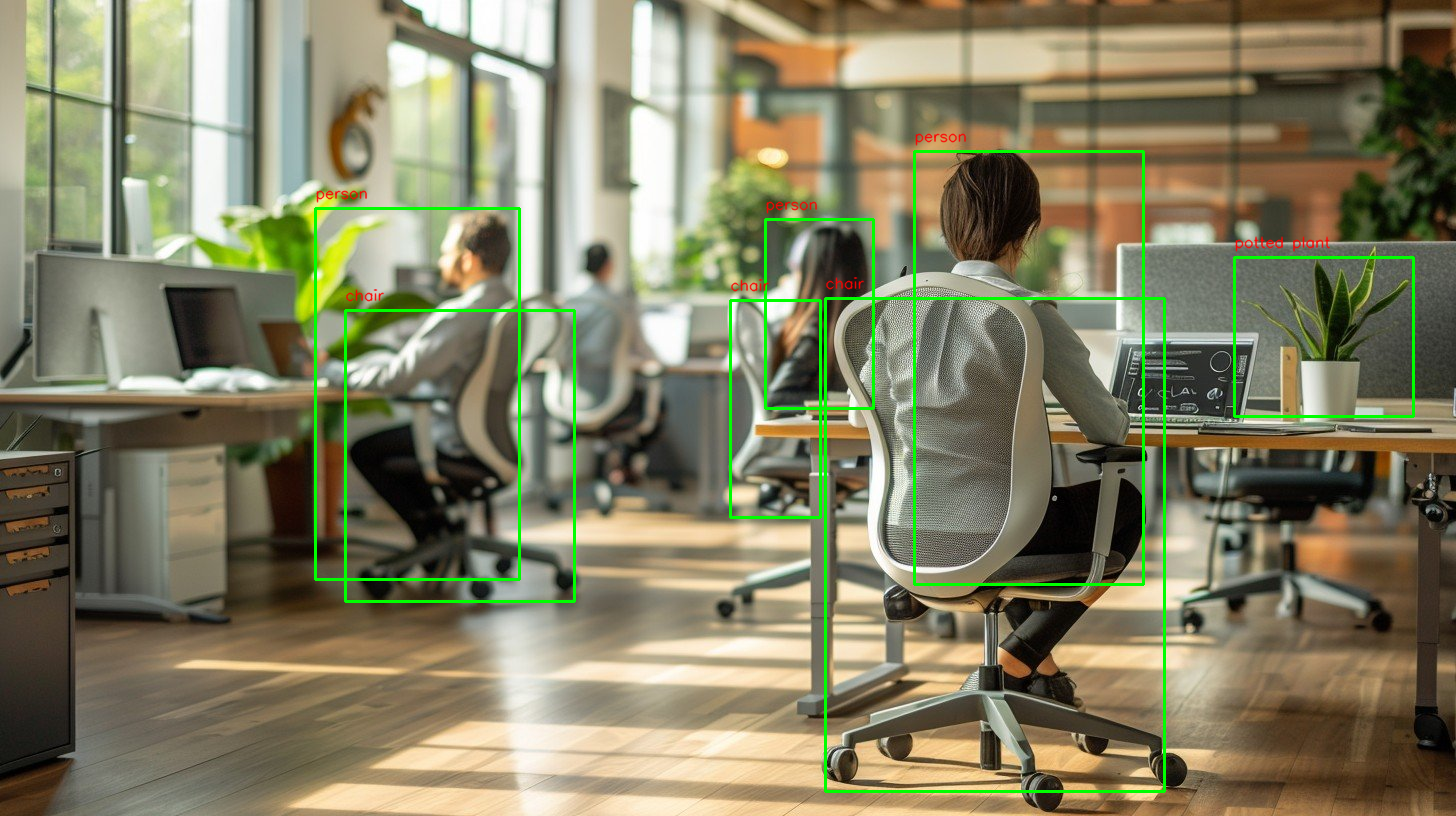

In [97]:
# show the image
cv2_imshow(igg)